In [42]:
import pandas as pd
import numpy as np

In [43]:
df = pd.read_csv("powerplant_data.csv")

In [44]:
df.isnull().sum()

AT    0
V     0
AP    0
RH    0
PE    0
dtype: int64

In [45]:
df.shape

(9568, 5)

In [46]:
X= df.drop("PE", axis=1)
y= df["PE"]

In [47]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test =train_test_split(X, y, test_size=0.2, random_state=42)

In [48]:
from sklearn.preprocessing import StandardScaler
scalar = StandardScaler()
X_train_scaled = scalar.fit_transform(X_train)
X_test_scaled = scalar.transform(X_test)

In [49]:
import torch
import torch.nn as nn

In [50]:
X_train_tensor = torch.tensor(X_train_scaled, dtype= torch.float32)
y_train_tensor = torch.tensor(y_train.values, dtype= torch.float32).view(-1,1)
X_test_tensor = torch.tensor(X_test_scaled, dtype= torch.float32)
y_test_tensor = torch.tensor(y_test.values, dtype= torch.float32).view(-1,1)

In [51]:
from torch.utils.data import DataLoader, TensorDataset
train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
test_dataset = TensorDataset(X_test_tensor, y_test_tensor)

In [52]:
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=32)

In [53]:
class ANN(nn.Module):
      def __init__(self):
          super(ANN,self).__init__()

          self.model = nn.Sequential(
              nn.Linear(X_train.shape[1], 6),
              nn.ReLU(),

              nn.Linear(6, 6),
              nn.ReLU(),

              nn.Linear(6,1),
          )

        
      def forward(self, x):
            return self.model(x)

In [54]:
import torch.optim as optim

model = ANN()
criteria = nn.MSELoss()
optimizer = optim.Adam(model.parameters())

In [55]:
#training
epochs = 100

train_loss = []
test_loss=[]
best_val_loss= float("inf")
for epoch in range(epochs):
    model.train()
    running_loss = 0.0
    for xb, yb in train_loader:
        optimizer.zero_grad()
        outputs= model(xb) # forward
        loss= criteria(outputs, yb) #loss cal
        loss.backward()#backward...  grad cal
        optimizer.step() #update the par
        
        running_loss += loss.item()
    avg_train= running_loss/len(train_loader)
    train_loss.append(avg_train)

#validation
    model.eval()
    running_val_loss= 0.0
    with torch.no_grad():
        for xb,yb in test_loader:
            outputs = model(xb)
            loss =criteria(outputs, yb)
            running_val_loss += loss.item()
        avg_test = running_val_loss/ len(test_loader)
        test_loss.append(avg_test)

    print(f"{epoch+1} avg_train {avg_train} avg_test {avg_test}")

    if best_val_loss > avg_test:
       best_val_loss= avg_test
       torch.save(model.state_dict(), "best_model.pt")

1 avg_train 205355.903515625 avg_test 201925.41510416666
2 avg_train 190248.55735677082 avg_test 172158.36666666667
3 avg_train 143889.39791666667 avg_test 113841.09908854167
4 avg_train 87707.81650390624 avg_test 67250.45221354166
5 avg_train 53712.062679036455 avg_test 42512.82858072917
6 avg_train 32954.66026204427 avg_test 24238.7296875
7 avg_train 17830.416912841796 avg_test 12514.626481119793
8 avg_train 10059.95823771159 avg_test 7964.024690755208
9 avg_train 6992.815649414062 avg_test 5768.198465983073
10 avg_train 5041.291828918457 avg_test 4125.358776855469
11 avg_train 3591.3747975667316 avg_test 2940.5780334472656
12 avg_train 2564.1779841105144 avg_test 2140.4873392740888
13 avg_train 1886.0392903645834 avg_test 1617.3908732096354
14 avg_train 1441.2302525838215 avg_test 1284.4300964355468
15 avg_train 1154.3185503641764 avg_test 1050.8872487386068
16 avg_train 940.878141784668 avg_test 868.3568328857422
17 avg_train 777.7336134592692 avg_test 722.9635050455729
18 avg_trai

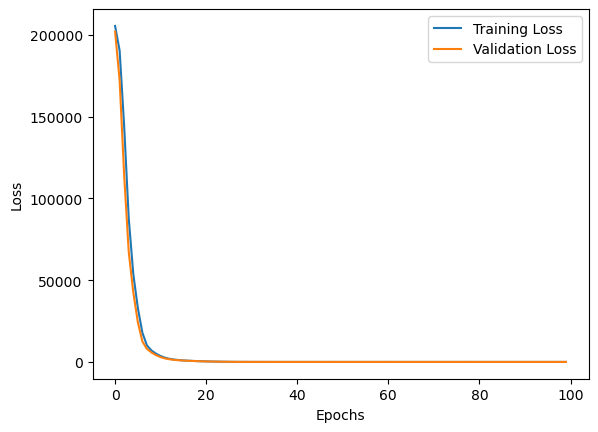

In [56]:
import matplotlib.pyplot as plt

plt.plot(train_loss, label="Training Loss")
plt.plot(test_loss, label="Validation Loss")

plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.show()

In [57]:
model.load_state_dict(torch.load("best_model.pt"))

<All keys matched successfully>

In [58]:
# Evaluation

model.eval()
with torch.no_grad():
    train_preds = model(X_train_tensor)
    test_preds = model(X_test_tensor)

    train_mse_loss = criteria(train_preds, y_train_tensor)
    test_mse_loss = criteria(test_preds, y_test_tensor)

print("Training MSE:", train_mse_loss.item())
print("Testing MSE:", test_mse_loss.item())

Training MSE: 21.271656036376953
Testing MSE: 19.566843032836914


In [59]:
from sklearn.metrics import r2_score

print("r^2 score =", r2_score(y_test, test_preds))

r^2 score = 0.9316189303158846


In [65]:
import pandas as pd
import numpy as np
predicted_df = pd.DataFrame(test_preds.numpy(), columns=["Predicted Values"])
actual_df = pd.DataFrame(y_test.values, columns=["Actual Values"])

pd.concat([predicted_df, actual_df], axis=1)

,Predicted Values,Actual Values
0,435.496216,433.27
1,436.817291,438.16
2,461.203217,458.42
3,475.940826,480.82
4,435.588013,441.41
...,...,...
1909,451.157562,456.70
1910,431.682892,438.04
1911,467.663788,467.80
1912,431.106201,437.14
